# Rydberg Kagome L4: full 128-geometry P(q) dataset

**Snapshot: 19 November 2026, 00:54 UTC.** These plots use the same **128 completed geometries (IDs 0–127)** for all three models, both detunings and all 30 drives: 23,040 cases. The planned production ensemble is complete: **128/128 geometries and 23,040/23,040 cases** at **chi_RG=12, D_MPS=128**. Six solver flags remain unresolved; these are not RG-converged predictions.

Each histogram contains 20,000 independent replica pairs from the lower-energy of two optimized states. P(q) below is **probability mass per allowed overlap**, averaged equally over geometries, without smoothing or symmetry folding. At N=48 there are 49 overlaps spaced by 1/24. The physical identity is

$$\langle q\rangle_{P_s}=q_{\mathrm{EA},s}=\frac1{48}\sum_i\langle Z_i\rangle_s^2.$$

**6 flagged cases are included and marked below.** For 4 cases, one start did not pass sweep stability within 120 sweeps, although the final energies and qEA agree closely between starts. Two additional cases (geometry 82, Full, Δ/V₀=2; geometry 86, NN+NNN, Δ/V₀=3.15; both at drive≈0.081677) still show observable drift or start disagreement. All six pass the sampling-moment check. Keeping these cases avoids a passing-only disorder selection; their numerical uncertainty remains unresolved. The table below lists every flagged input.

All plotting data are embedded in this notebook. Re-execution requires only NumPy and Matplotlib, with no cluster access or checkpoint downloads.

In [1]:
import base64, hashlib, io, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

METADATA = json.loads('{"snapshot_utc": "20261119T005408Z", "source_run": "/root/autodl-tmp/spin-glasses/runs/rydberg-L4-production-20261117-v5", "source_release": "rydberg-kagome-20261117-v5", "chi": 12, "D": 128, "sample_ids": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127], "cohort_rule": "All 180 cases completed; retain flagged cases, no passing-only selection", "case_count": 23040, "flags": [{"case": "s025_nn_d2_g29_c12_D128", "sample": 25, "model": "nn", "delta": 2.0, "omega": 10.0, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 4.736951571734001e-15, "qea_difference": 5.273559366969494e-16, "passed": true}}, {"case": "s038_nn_d3.15_g28_c12_D128", "sample": 38, "model": "nn", "delta": 3.15, "omega": 8.184726679935508, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 3.552713678800501e-15, "qea_difference": 6.938893903907228e-18, "passed": true}}, {"case": "s076_nn_d2_g27_c12_D128", "sample": 76, "model": "nn", "delta": 2.0, "omega": 6.698975082524823, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 4.144832625267251e-15, "qea_difference": 3.469446951953614e-16, "passed": true}}, {"case": "s076_nn_d3.15_g29_c12_D128", "sample": 76, "model": "nn", "delta": 3.15, "omega": 10.0, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 2.3684757858670005e-15, "qea_difference": 8.604228440844963e-16, "passed": true}}, {"case": "s082_full_d2_g05_c12_D128", "sample": 82, "model": "full", "delta": 2.0, "omega": 0.08167710739045757, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 1.4546023644849507e-10, "qea_difference": 0.001477679694708911, "passed": false}}, {"case": "s086_nn_nnn_d3.15_g05_c12_D128", "sample": 86, "model": "nn_nnn", "delta": 3.15, "omega": 0.08167710739045757, "solver_pass": false, "sampling_pass": true, "start_comparison": {"energy_per_spin": 2.1239090486346868e-09, "qea_difference": 0.004096443420762097, "passed": false}}], "pairs_per_case": 20000, "files": {"histograms.npz": "da3228954689e07ef3bb0f1fef78259af9f1e32e52e00e80a8b6d2396059541c"}}')
PAYLOAD = '...'
raw = base64.b64decode(PAYLOAD)
assert hashlib.sha256(raw).hexdigest() == METADATA['files']['histograms.npz']
with np.load(io.BytesIO(raw), allow_pickle=False) as data:
    arrays = {key: data[key].copy() for key in data.files}
counts, qea, passed = arrays['counts'], arrays['qea'], arrays['passed']
q, drives, deltas = arrays['q'], arrays['drives'], arrays['deltas']
sample_ids = arrays['sample_ids']
# Axes: geometry, model, detuning, drive, overlap (last axis for histograms).
p = counts / counts.sum(axis=-1, keepdims=True)
mean_p = p.mean(axis=0)
mean_qea = qea.mean(axis=0)
assert counts.shape == (len(sample_ids), 3, 2, 30, 49)
assert np.all(counts.sum(axis=-1) == 20000)
np.testing.assert_allclose(mean_p.sum(axis=-1), 1)
labels = ['Full', 'NN+NNN', 'NN']
colors = ['#24578a', '#cc7924', '#26856c']
print(f'{len(sample_ids)} geometries; {passed.size} cases; {(~passed).sum()} flagged cases retained.')

flag_points = []
for flag in METADATA['flags']:
    m = list(arrays['models']).index(flag['model'])
    d = int(np.argmin(abs(deltas-flag['delta'])))
    k = int(np.argmin(abs(drives-flag['omega'])))
    flag_points.append((m,d,k,flag['sample']))
assert (~passed).sum() == len(METADATA['flags'])


flag_table = ['| Geometry | Model | Δ/V₀ | Ω/V₀ | Two starts agree | Sampling check |',
              '|---:|---|---:|---:|---|---|']
for flag in METADATA['flags']:
    model_label = labels[list(arrays['models']).index(flag['model'])]
    agreement = 'Yes' if flag['start_comparison']['passed'] else 'No'
    sampling_check = 'Pass' if flag['sampling_pass'] else 'Fail'
    flag_table.append(f"| {flag['sample']} | {model_label} | {flag['delta']:g} | {flag['omega']:.6g} | {agreement} | {sampling_check} |")
display(Markdown('\n'.join(flag_table)))

# Apply the base style first so it cannot override the figure settings.
plt.style.use('default')
plt.rcParams.update({
    'text.usetex': True, 'text.latex.preamble': r'\usepackage{amsmath}',
    'font.family': 'serif', 'font.size': 11,
    'axes.labelsize': 11, 'axes.titlesize': 12, 'figure.titlesize': 12,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'figure.dpi': 120, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.linewidth': .8, 'axes.autolimit_mode': 'data',
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'axes.spines.top': True, 'axes.spines.right': True,
    'axes.spines.bottom': True, 'axes.spines.left': True,
})


128 geometries; 23040 cases; 6 flagged cases retained.


| Geometry | Model | Δ/V₀ | Ω/V₀ | Two starts agree | Sampling check |
|---:|---|---:|---:|---|---|
| 25 | NN | 2 | 10 | Yes | Pass |
| 38 | NN | 3.15 | 8.18473 | Yes | Pass |
| 76 | NN | 2 | 6.69898 | Yes | Pass |
| 76 | NN | 3.15 | 10 | Yes | Pass |
| 82 | Full | 2 | 0.0816771 | No | Pass |
| 86 | NN+NNN | 3.15 | 0.0816771 | No | Pass |

## 1. Evolution of P(q) across the drive range

Rows correspond to detuning; columns to interaction model. A common logarithmic color scale shows the probability mass in each overlap bin. Zero-probability bins are white; positive masses below 1e-4 use the bottom color. The dashed black line is the deterministic disorder-averaged qEA, not a fitted peak position. Red crosses identify model/detuning/drive points containing flagged cases.

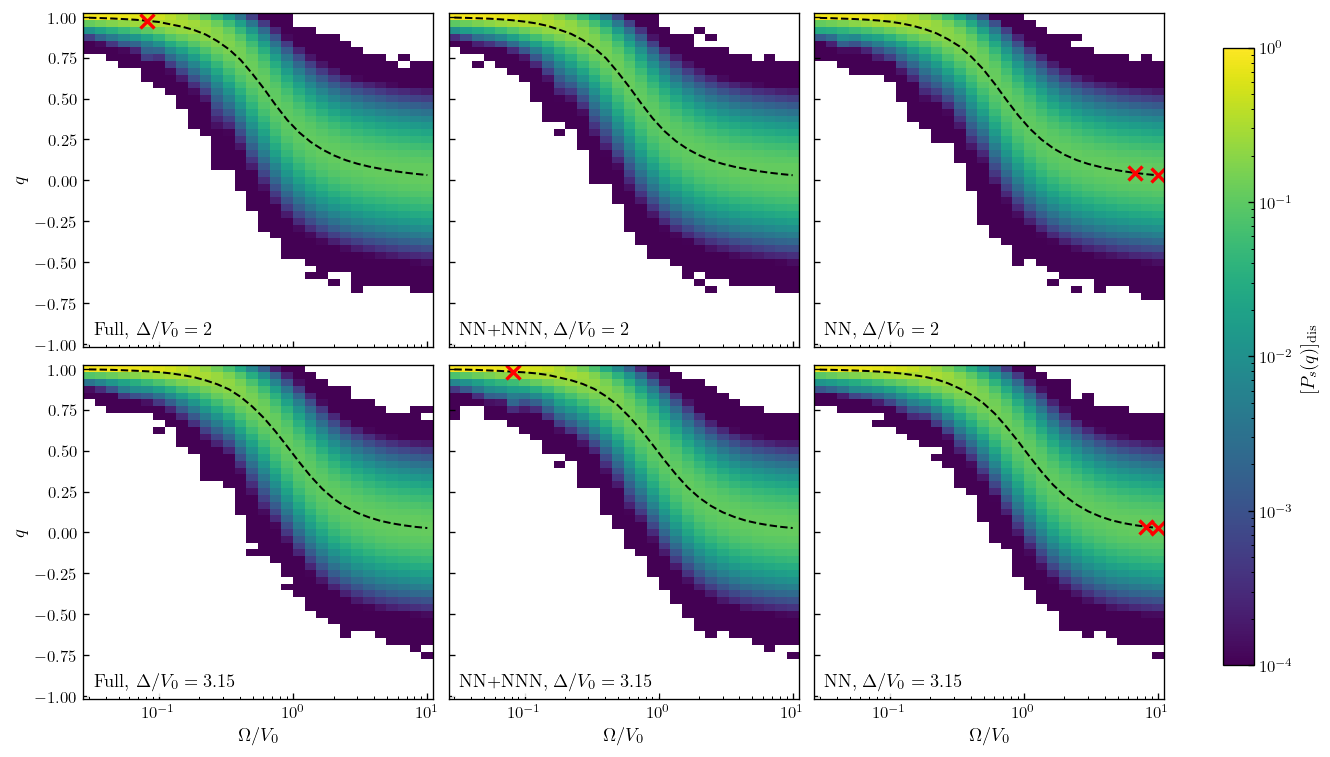

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True, constrained_layout=True)
log_g = np.log(drives)
g_edges = np.exp(np.r_[log_g[0]-(log_g[1]-log_g[0])/2,
                       (log_g[:-1]+log_g[1:])/2,
                       log_g[-1]+(log_g[-1]-log_g[-2])/2])
dq = q[1]-q[0]
q_edges = np.r_[q-dq/2, q[-1]+dq/2]
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('white')
for d in range(2):
    for m in range(3):
        ax = axes[d,m]
        image = ax.pcolormesh(g_edges, q_edges, np.ma.masked_equal(mean_p[m,d].T, 0),
                             cmap=cmap, norm=LogNorm(vmin=1e-4, vmax=1), shading='flat')
        ax.plot(drives, mean_qea[m,d], 'k--', lw=1.2)
        ax.set_xscale('log')
        ax.set_xlim(g_edges[0], g_edges[-1])
        ax.set_ylim(-1-dq/2, 1+dq/2)
        ax.text(.03,.04, rf'{labels[m]}, $\Delta/V_0 = {deltas[d]:g}$', transform=ax.transAxes,
                color='black', bbox=dict(facecolor='white', alpha=.85, edgecolor='none'))
        if m==0: ax.set_ylabel(r'$q$')
        if d==1: ax.set_xlabel(r'$\Omega/V_0$')
for m,d,k,sid in flag_points:
    axes[d,m].plot(drives[k], mean_qea[m,d,k], 'x', color='red', ms=8, mew=2)
fig.colorbar(image, ax=axes, label=r'$[P_s(q)]_{\mathrm{dis}}$', shrink=.9)
plt.show()


## 2. Direct comparison at selected drives

Each panel uses the nearest production-grid point to the indicated representative scale (0.03, 0.3, 1, 10); annotations give the actual drive. Lines connect discrete masses and do not represent smoothing. All curves use the same 128 geometries. The selected slices include flagged NN inputs at drive 10 for both detunings. The other flagged inputs are at drives outside these selected slices. All flags are listed in the snapshot table and marked in the full drive scans. These panels display shapes; their model differences have not yet been established as RG-converged.

**Disorder error bars:** curves show the mean across the same 128 geometries. Shading and error bars show **± one sample standard deviation across geometries**, using ddof=1. Bars are drawn at every third overlap bin for readability; the band covers every bin. This is disorder spread, not the standard error or a 95% confidence interval for the mean. The observed histogram spread also includes finite Born-sampling noise. Negative lower error limits are statistical intervals, not negative probability masses; they are not clipped.


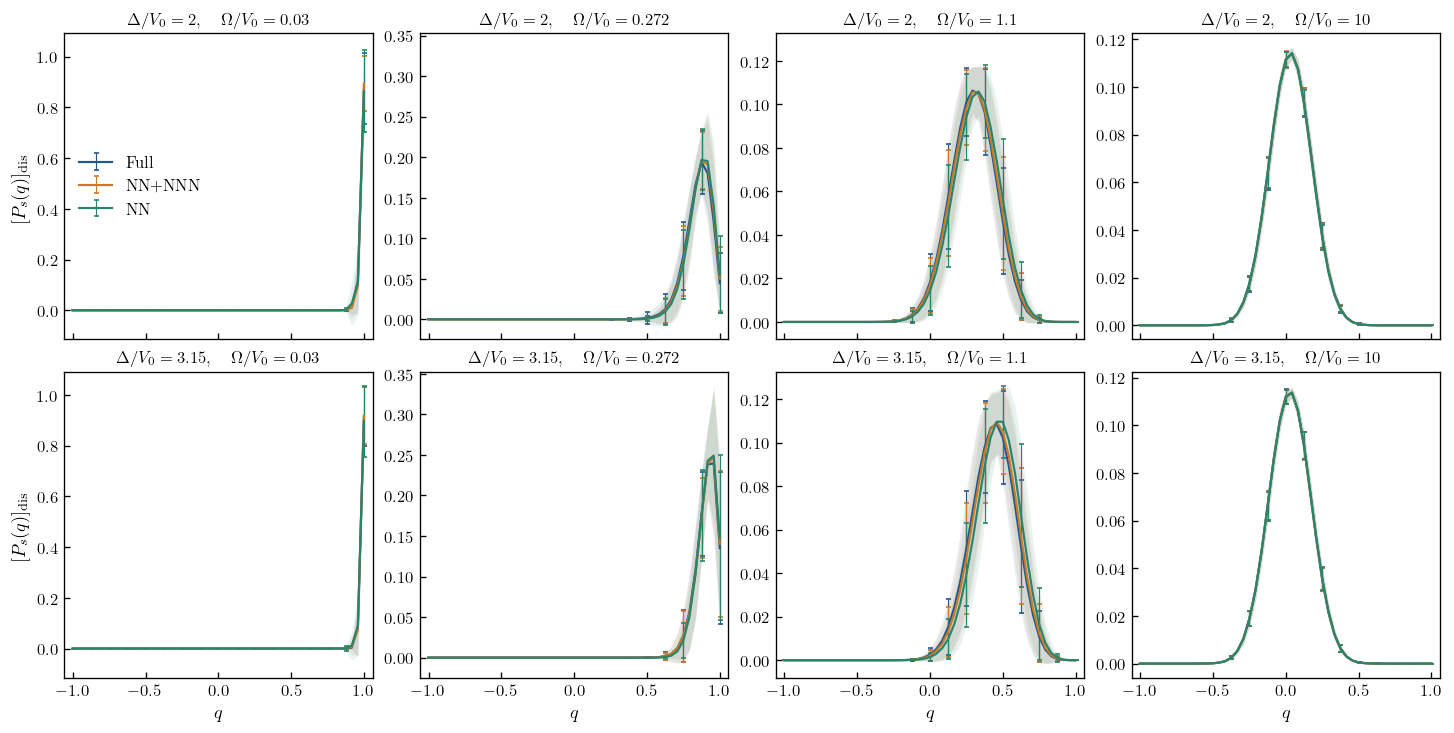

In [3]:
indices = [int(np.argmin(abs(np.log(drives/x)))) for x in [.03,.3,1.,10.]]
sd_p = p.std(axis=0, ddof=1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey='col', constrained_layout=True)
for d in range(2):
    for col,k in enumerate(indices):
        ax = axes[d,col]
        for m in range(3):
            ax.errorbar(q, mean_p[m,d,k], yerr=sd_p[m,d,k], color=colors[m],
                        lw=1.3, elinewidth=.7, capsize=1.5, errorevery=3, label=labels[m])
            ax.fill_between(q, mean_p[m,d,k]-sd_p[m,d,k],
                            mean_p[m,d,k]+sd_p[m,d,k], color=colors[m], alpha=.10, lw=0)
        ax.set_title(rf'$\Delta/V_0={deltas[d]:g},\quad \Omega/V_0={drives[k]:.3g}$', fontsize=10)
        ax.set_xlim(-1.06,1.06)
        # Match detunings within each column and retain the full mean +/- SD.
        lower = min(0., float((mean_p[:,:,k] - sd_p[:,:,k]).min()))
        upper = float((mean_p[:,:,k] + sd_p[:,:,k]).max())
        pad = .05 * (upper - lower)
        ax.set_ylim(lower - pad, upper + pad)
        if col==0: ax.set_ylabel(r'$[P_s(q)]_{\mathrm{dis}}$')
        if d==1: ax.set_xlabel(r'$q$')
axes[0,0].legend(loc='center left', fontsize=10, frameon=False)
plt.show()


## 3. Geometry-to-geometry spread of qEA

Error bars show **mean ± one sample standard deviation across the 128 geometries**, at every drive point. These quantify the spread between geometries, not uncertainty in the mean. The same geometry cohort is used for every curve, including the flagged cases marked by red crosses. The following section retains the separate pointwise 95% bootstrap intervals for the disorder mean.

$$
\bar x=\frac1S\sum_{s=1}^{S}x_s,\qquad
s_x=\sqrt{\frac1{S-1}\sum_{s=1}^{S}(x_s-\bar x)^2},\qquad S=128.
$$

The standard error would be s_x/sqrt(S); it is not the quantity shown in these error bars. Neither measure includes RG systematic uncertainty.

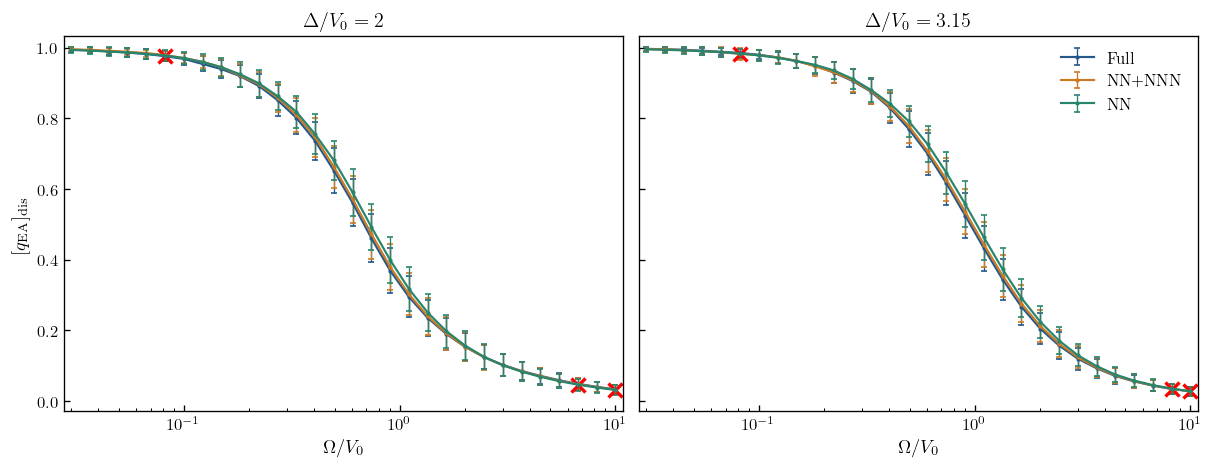

In [4]:
sd_qea = qea.std(axis=0, ddof=1)
qea_lower = min(0., float((mean_qea - sd_qea).min()))
qea_upper = max(1., float((mean_qea + sd_qea).max()))
fig, axes = plt.subplots(1,2,figsize=(10,3.8),sharey=True,constrained_layout=True)
for d,ax in enumerate(axes):
    for m in range(3):
        ax.errorbar(drives, mean_qea[m,d], yerr=sd_qea[m,d],
                    color=colors[m], label=labels[m], lw=1.3,
                    elinewidth=.8, capsize=2, marker='.', markersize=3)
    ax.set_xscale('log')
    ax.set_xlabel(r'$\Omega/V_0$')
    ax.set_xlim(drives[0] / 1.08, drives[-1] * 1.08)
    ax.set_ylim(qea_lower - .03, qea_upper + .03)
    ax.set_title(rf'$\Delta/V_0={deltas[d]:g}$')
axes[0].set_ylabel(r'$[q_{\mathrm{EA}}]_{\mathrm{dis}}$')
for m,d,k,sid in flag_points:
    axes[d].plot(drives[k],mean_qea[m,d,k],'x',color='red',ms=8,mew=2)
axes[1].legend(frameon=False)
plt.show()


## 4. Mean qEA and both drive derivatives

The same figure compares three quantities, with one column per detuning:

1. $Q_L=[q_{\mathrm{EA}}]_{\mathrm{dis}}$;
2. $R_{\ln g}=-dQ_L/d\ln g$, the response to a fractional increase in drive;
3. $R_g=-dQ_L/dg$, the response to an absolute increase in drive, where $g=\Omega/V_0$.

All horizontal axes are logarithmic; all vertical axes are linear. **No logarithm of the derivative is taken.** In the continuum $R_{\ln g}=gR_g$, so their maxima generally differ.

**Finite differences, no smoothing:** differentiate each geometry first, then average the same 128 matched geometries. The logarithmic derivative uses centered differences on the uniformly spaced natural-log grid. The linear-drive derivative uses `np.gradient(qea, drives, axis=-1, edge_order=1)`: interior three-point, second-order differences with the actual unequal drive spacings. Both use first-order one-sided differences at endpoints (open circles). These independently discretized derivatives obey the chain rule only up to finite-grid error. Adjacent drives differ by about 22%; peak markers and tables use interior grid maxima without sub-grid fitting.

Shading in all rows gives **pointwise 95% percentile bootstrap intervals for the disorder mean**: 2,000 common whole-curve geometry resamples, seed 20261117, shared across models, detunings, and observables. Whole-curve resampling preserves drive correlations. These are distinct from disorder standard deviations in Section 3 and exclude RG, solver, and finite-difference systematic errors. The tables give central 95% bootstrap ranges of the discrete interior peak drive, not sub-grid confidence limits.

**Diamonds:** derivative maxima. **Dotted lines:** the corresponding peak drive within each derivative row. **Red crosses:** flagged qEA inputs and every derivative stencil that uses one; the nonuniform linear-drive stencil can also depend on its central input. All flagged geometries remain included. The stronger response locates a finite-size crossover/candidate-transition region, not proof of a second-order transition or glass order. qEA contains longitudinal polarization; RG sensitivity at chi12/D128 remains unresolved.


Adjacent drives differ by a factor 1.2218; grid-peak locations have finite resolution.
Bootstrap ranges describe disorder resampling only, not numerical systematic errors.
NN, Δ=2, drive=10: omitting geometry 25 changes mean CDF by 0.000308.
NN, Δ=3.15, drive=8.1847: omitting geometry 38 changes mean CDF by 0.000074.
NN, Δ=2, drive=6.699: omitting geometry 76 changes mean CDF by 0.000409.
NN, Δ=3.15, drive=10: omitting geometry 76 changes mean CDF by 0.000230.
Full, Δ=2, drive=0.081677: omitting geometry 82 changes mean CDF by 0.001374.
NN+NNN, Δ=3.15, drive=0.081677: omitting geometry 86 changes mean CDF by 0.003531.
These omission sensitivities change the cohort; they are not corrections or bounds on solver error.


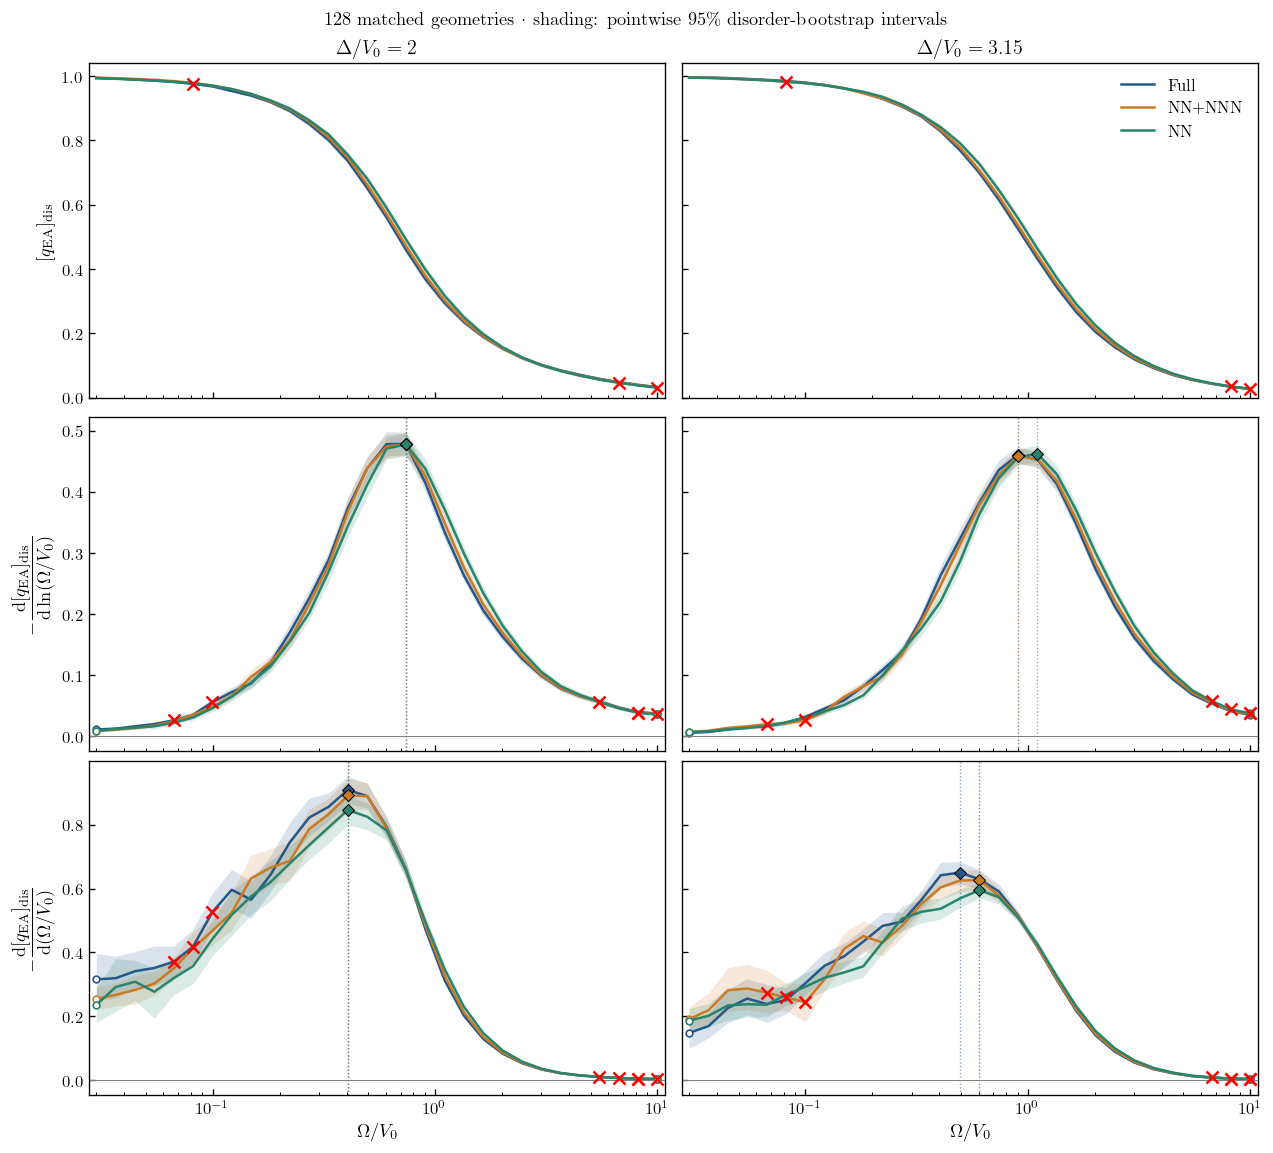

### Logarithmic-drive derivative

| Model | Detuning | Peak drive (grid) | 95% bootstrap grid-peak range | Peak height |
|---|---:|---:|---:|---:|
| Full | 2 | 0.7397 | 0.6054–0.7397 | 0.4784 |
| Full | 3.15 | 0.9038 | 0.9038–1.104 | 0.4601 |
| NN+NNN | 2 | 0.7397 | 0.6054–0.7397 | 0.4775 |
| NN+NNN | 3.15 | 0.9038 | 0.9038–1.104 | 0.4589 |
| NN | 2 | 0.7397 | 0.6054–0.7397 | 0.4775 |
| NN | 3.15 | 1.104 | 0.9038–1.104 | 0.4620 |

### Linear-drive derivative

| Model | Detuning | Peak drive (grid) | 95% bootstrap grid-peak range | Peak height |
|---|---:|---:|---:|---:|
| Full | 2 | 0.4056 | 0.4056–0.4955 | 0.9090 |
| Full | 3.15 | 0.4955 | 0.4056–0.6054 | 0.6499 |
| NN+NNN | 2 | 0.4056 | 0.4056–0.4955 | 0.8915 |
| NN+NNN | 3.15 | 0.6054 | 0.4056–0.6054 | 0.6263 |
| NN | 2 | 0.4056 | 0.4056–0.4955 | 0.8459 |
| NN | 3.15 | 0.6054 | 0.6054–0.6054 | 0.5951 |

| Model | Detuning | qEA at lowest drive | qEA at highest drive |
|---|---:|---:|---:|
| Full | 2 | 0.99422 | 0.03257 |
| Full | 3.15 | 0.99630 | 0.02698 |
| NN+NNN | 2 | 0.99509 | 0.03172 |
| NN+NNN | 3.15 | 0.99627 | 0.02701 |
| NN | 2 | 0.99309 | 0.03083 |
| NN | 3.15 | 0.99507 | 0.02724 |

In [5]:
log_drive = np.log(drives)
h = float(np.diff(log_drive).mean())
np.testing.assert_allclose(np.diff(log_drive), h, rtol=1e-12, atol=1e-14)
derivative_by_geometry = -np.gradient(qea, h, axis=-1, edge_order=1)
mean_derivative = derivative_by_geometry.mean(axis=0)
np.testing.assert_allclose(mean_derivative,
                           -np.gradient(mean_qea, h, axis=-1, edge_order=1), atol=2e-14)

rng = np.random.default_rng(20261117)
resamples = rng.integers(0, len(sample_ids), size=(2000, len(sample_ids)))
# Bounded batches keep intermediate resampled arrays small.
bootstrap = np.concatenate([qea[batch].mean(axis=1)
                            for batch in np.array_split(resamples, 20)], axis=0)
bootstrap_derivative = np.concatenate([derivative_by_geometry[batch].mean(axis=1)
                                       for batch in np.array_split(resamples, 20)], axis=0)
np.testing.assert_allclose(bootstrap_derivative,
                           -np.gradient(bootstrap, h, axis=-1, edge_order=1), atol=2e-14)
lo, hi = np.quantile(bootstrap, [.025, .975], axis=0)
derivative_lo, derivative_hi = np.quantile(bootstrap_derivative, [.025, .975], axis=0)
peak_indices = np.argmax(mean_derivative[..., 1:-1], axis=-1) + 1
bootstrap_peak_indices = np.argmax(bootstrap_derivative[..., 1:-1], axis=-1) + 1
# Nearest-rank quantiles stay on the sampled drive grid (NumPy-version compatible).
ordered_peak_drives = np.sort(drives[bootstrap_peak_indices], axis=0)
quantile_rows = np.rint(np.array([.025, .975]) * (len(resamples)-1)).astype(int)
peak_drive_lo, peak_drive_hi = ordered_peak_drives[quantile_rows]


# Direct derivative on the nonuniform linear-drive grid.
linear_by_geometry = -np.gradient(qea, drives, axis=-1, edge_order=1)
mean_linear = linear_by_geometry.mean(axis=0)
bootstrap_linear = np.concatenate([linear_by_geometry[batch].mean(axis=1)
                                  for batch in np.array_split(resamples, 20)], axis=0)
np.testing.assert_allclose(mean_linear, -np.gradient(mean_qea, drives, axis=-1), atol=1e-13)
np.testing.assert_allclose(bootstrap_linear, -np.gradient(bootstrap, drives, axis=-1), atol=1e-13)
linear_lo, linear_hi = np.quantile(bootstrap_linear, [.025, .975], axis=0)
linear_peaks = np.argmax(mean_linear[..., 1:-1], axis=-1) + 1
linear_bootstrap_peaks = np.argmax(bootstrap_linear[..., 1:-1], axis=-1) + 1
linear_peak_lo, linear_peak_hi = np.sort(drives[linear_bootstrap_peaks], axis=0)[quantile_rows]

diagnostics = [
    dict(name='Logarithmic-drive derivative', mean=mean_derivative,
         low=derivative_lo, high=derivative_hi, peaks=peak_indices,
         peak_low=peak_drive_lo, peak_high=peak_drive_hi,
         operator=-np.gradient(np.eye(len(drives)), h, axis=0),
         ylabel=r'$-\dfrac{\mathrm{d}[q_{\mathrm{EA}}]_{\mathrm{dis}}}{\mathrm{d}\ln(\Omega/V_0)}$'),
    dict(name='Linear-drive derivative', mean=mean_linear,
         low=linear_lo, high=linear_hi, peaks=linear_peaks,
         peak_low=linear_peak_lo, peak_high=linear_peak_hi,
         operator=-np.gradient(np.eye(len(drives)), drives, axis=0),
         ylabel=r'$-\dfrac{\mathrm{d}[q_{\mathrm{EA}}]_{\mathrm{dis}}}{\mathrm{d}(\Omega/V_0)}$')]

fig, axes = plt.subplots(3, 2, figsize=(10.5, 9.5), sharex='col', sharey='row',
                         constrained_layout=True)
for d in range(len(deltas)):
    upper = axes[0,d]
    for m in range(len(labels)):
        upper.plot(drives, mean_qea[m,d], color=colors[m], label=labels[m])
        upper.fill_between(drives, lo[m,d], hi[m,d], color=colors[m], alpha=.17, lw=0)
    upper.set_title(rf'$\Delta/V_0 = {deltas[d]:g}$')
    upper.set_ylim(0, 1.04)
    for row, diagnostic in enumerate(diagnostics, start=1):
        ax = axes[row,d]
        for m in range(len(labels)):
            values = diagnostic['mean'][m,d]
            ax.plot(drives, values, color=colors[m], lw=1.5)
            ax.fill_between(drives, diagnostic['low'][m,d], diagnostic['high'][m,d],
                            color=colors[m], alpha=.17, lw=0)
            ax.plot(drives[[0,-1]], values[[0,-1]], 'o', color=colors[m], mfc='white', ms=4)
            k = diagnostic['peaks'][m,d]
            ax.plot(drives[k], values[k], 'D', color=colors[m], mec='black', mew=.6, ms=5, zorder=5)
            ax.axvline(drives[k], color=colors[m], ls=':', lw=.8, alpha=.55)
        ax.axhline(0, color='.5', lw=.6)
    axes[-1,d].set_xscale('log')
    axes[-1,d].set_xlim(drives[0] / 1.08, drives[-1] * 1.08)
    axes[-1,d].set_xlabel(r'$\Omega/V_0$')
for m,d,k,sid in flag_points:
    axes[0,d].plot(drives[k], mean_qea[m,d,k], 'x', color='red', ms=7, mew=1.5)
    for row, diagnostic in enumerate(diagnostics, start=1):
        affected = np.flatnonzero(abs(diagnostic['operator'][:,k]) > 1e-14)
        axes[row,d].plot(drives[affected], diagnostic['mean'][m,d,affected],
                         'x', color='red', ms=7, mew=1.5)
axes[0,0].set_ylabel(r'$[q_{\mathrm{EA}}]_{\mathrm{dis}}$')
for row, diagnostic in enumerate(diagnostics, start=1):
    axes[row,0].set_ylabel(diagnostic['ylabel'])
axes[0,1].legend(frameon=False)
fig.suptitle(rf'{len(sample_ids)} matched geometries $\cdot$ shading: pointwise 95\% disorder-bootstrap intervals', fontsize=11)
plt.show()

for diagnostic in diagnostics:
    table = [f"### {diagnostic['name']}", '',
             '| Model | Detuning | Peak drive (grid) | 95% bootstrap grid-peak range | Peak height |',
             '|---|---:|---:|---:|---:|']
    for m in range(len(labels)):
        for d in range(len(deltas)):
            k = diagnostic['peaks'][m,d]
            table.append(f'| {labels[m]} | {deltas[d]:g} | {drives[k]:.4g} | '
                         f"{diagnostic['peak_low'][m,d]:.4g}–{diagnostic['peak_high'][m,d]:.4g} | "
                         f"{diagnostic['mean'][m,d,k]:.4f} |")
    display(Markdown('\n'.join(table)))
print(f'Adjacent drives differ by a factor {np.exp(h):.4f}; grid-peak locations have finite resolution.')
print('Bootstrap ranges describe disorder resampling only, not numerical systematic errors.')

# Quantitative snapshot and sensitivity to flagged geometries.
table=['| Model | Detuning | qEA at lowest drive | qEA at highest drive |',
       '|---|---:|---:|---:|']
for m in range(3):
    for d in range(2):
        table.append(f'| {labels[m]} | {deltas[d]:g} | {mean_qea[m,d,0]:.5f} | {mean_qea[m,d,-1]:.5f} |')
display(Markdown('\n'.join(table)))

for m,d,k,sid in flag_points:
    reduced = p[sample_ids != sid,m,d,k].mean(axis=0)
    shift = np.max(abs(np.cumsum(mean_p[m,d,k])-np.cumsum(reduced)))
    print(f'{labels[m]}, Δ={deltas[d]:g}, drive={drives[k]:.5g}: omitting geometry {sid} changes mean CDF by {shift:.6f}.')
print('These omission sensitivities change the cohort; they are not corrections or bounds on solver error.')


### Separate linear-drive derivative figure

The last row above is reproduced with a common vertical scale for $\Delta/V_0=2$ and $3.15$. The legend identifies Full, NN+NNN, and NN interactions. Shading denotes pointwise 95% disorder-bootstrap intervals; diamonds mark interior grid maxima, dotted lines their drive positions, open circles the endpoints, and red crosses derivative stencils containing flagged inputs. All data and uncertainty estimates are identical to Section 4.


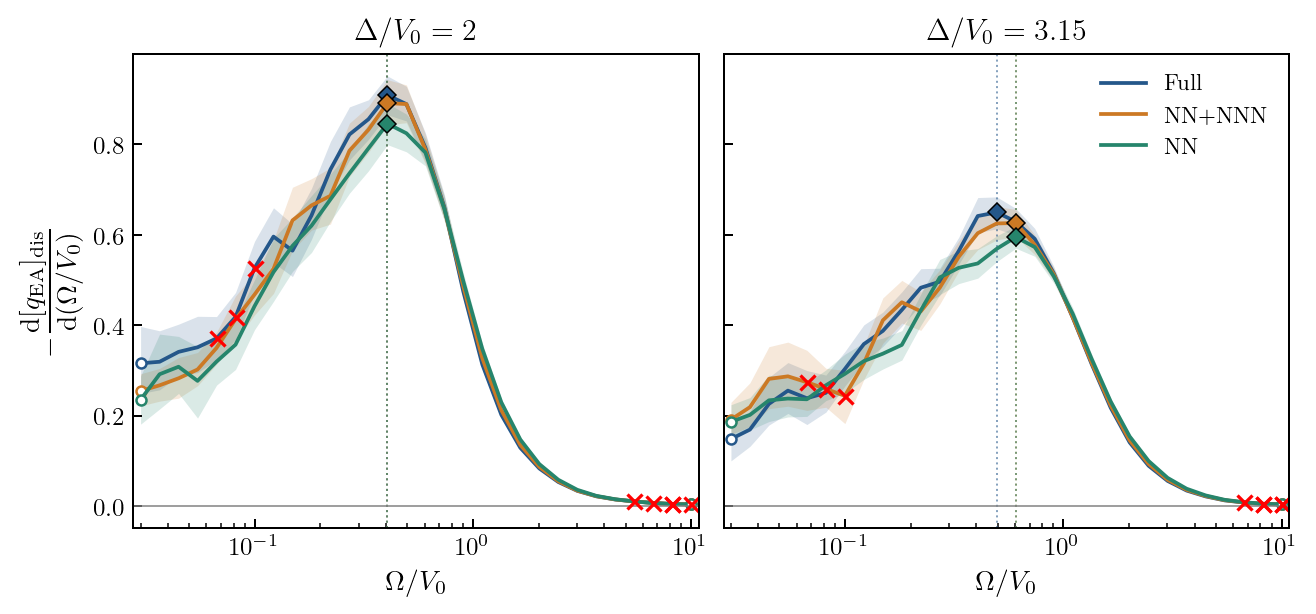

In [ ]:
linear_diagnostic = diagnostics[1]
fig_linear, axes_linear = plt.subplots(1, 2, figsize=(7.2, 3.3),
                                      sharex=True, sharey=True, constrained_layout=True)
for d, ax in enumerate(axes_linear):
    for m, label in enumerate(labels):
        values = mean_linear[m,d]
        ax.plot(drives, values, color=colors[m], lw=1.5, label=label)
        ax.fill_between(drives, linear_lo[m,d], linear_hi[m,d],
                        color=colors[m], alpha=.17, lw=0)
        ax.plot(drives[[0,-1]], values[[0,-1]], 'o', color=colors[m],
                mfc='white', ms=4)
        k = linear_peaks[m,d]
        ax.plot(drives[k], values[k], 'D', color=colors[m],
                mec='black', mew=.6, ms=5, zorder=5)
        ax.axvline(drives[k], color=colors[m], ls=':', lw=.8, alpha=.55)
    ax.axhline(0, color='.5', lw=.6)
    ax.set_xscale('log')
    ax.set_xlim(drives[0] / 1.08, drives[-1] * 1.08)
    ax.set_xlabel(r'$\Omega/V_0$')
    ax.set_title(rf'$\Delta/V_0={deltas[d]:g}$')
for m, d, k, sid in flag_points:
    affected = np.flatnonzero(abs(linear_diagnostic['operator'][:,k]) > 1e-14)
    axes_linear[d].plot(drives[affected], mean_linear[m,d,affected],
                        'x', color='red', ms=6, mew=1.3)
axes_linear[0].set_ylabel(linear_diagnostic['ylabel'])
axes_linear[1].legend(loc='upper right', frameon=False, fontsize=9)
plt.show()


## 5. Raw overlap Binder cumulant at L=4

For each geometry $s$, recover the **sampled** overlap moments directly from its full, signed histogram:

$$m_{k,s}(g)=\sum_q P_s(q;g)q^k,\qquad
B_L(g)=\frac12\left(3-\frac{[m_{4,s}(g)]_{\rm dis}}
{[m_{2,s}(g)]_{\rm dis}^{\,2}}\right),\qquad L=4\;(N=48).$$

The brackets give equal weight to all **128 matched geometries**. This is the **ratio of disorder-averaged moments**, not the disorder average of per-geometry ratios. Both numerator and denominator come from the same saved 20,000-pair histograms; the deterministic `qea` and `q2` arrays are not substituted into this estimator. No centering, folding or smoothing is applied. The alternative normalization $U=1-[m_4]/(3[m_2]^2)$ satisfies $B_L=3U/2$.

One panel per detuning compares Full, NN+NNN and NN at all 30 production drives. Shading gives **pointwise 95% percentile disorder-bootstrap intervals**, recomputing the complete nonlinear ratio in each of 2,000 whole-curve geometry resamples (seed 20261117; the same resamples as Section 4, shared across models and detunings). These are intervals for the disorder estimator, not geometry-to-geometry standard deviations or simultaneous bands. They do not separately quantify finite Born-sampling error or bound solver/RG systematic errors. All geometries remain included; **red crosses** mark curve points containing one or more of the six flagged cases.

**Interpretation:** longitudinal polarization gives $\langle q\rangle_s=q_{{\rm EA},s}>0$ even without glass order. A narrow distribution at any nonzero overlap has $B_L\to1$, so a large raw Binder alone is not evidence of a glass. These six curves characterize one finite size; they cannot provide a crossing between sizes or establish a critical drive. RG sensitivity at chi12/D128 and the six solver flags remain unresolved.

For quantum overlap moments and an alternative disorder-averaging convention, see [Mukherjee, Rajak and Chakrabarti, PRE 92, 042107 (2015), Eqs. (4) and (6)](https://arxiv.org/html/1412.2973v2). For the additional issues with Binder diagnostics in a field, see [Feng et al., arXiv:1403.4560, Eq. (3)](https://arxiv.org/html/1403.4560v1); their centered definition differs from the raw definition plotted here.


Ratio of disorder-averaged histogram moments; all 128 geometries retained.
Bootstrap intervals exclude solver/RG systematics; Born-sampling error is not separately estimated.


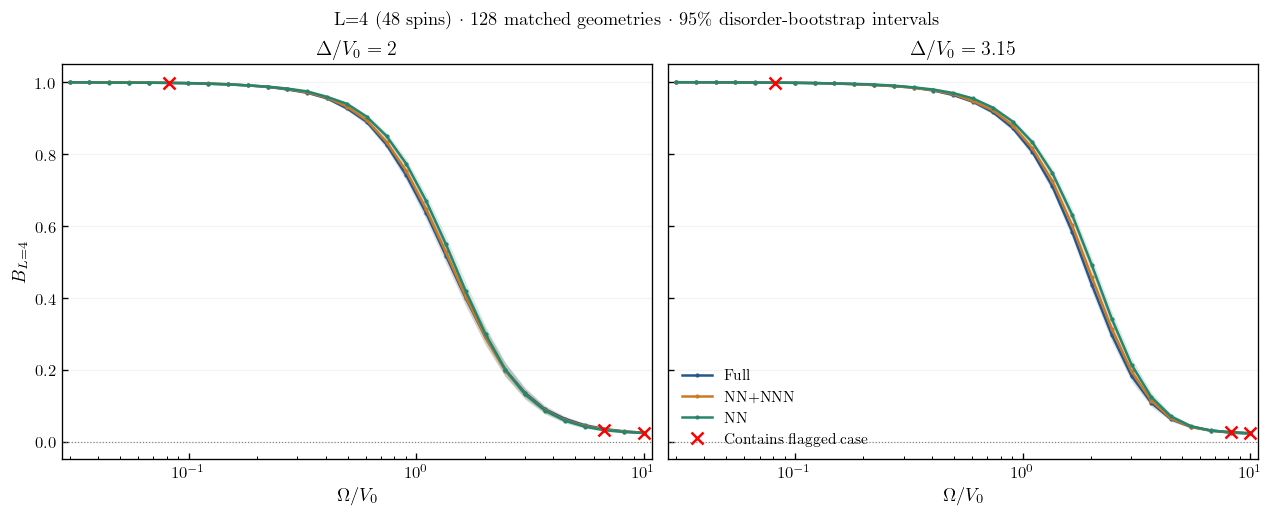

In [6]:
# Moments of the physical two-replica overlap, estimated from saved histograms.
binder_m2 = np.einsum('smdkq,q->smdk', p, q**2)
binder_m4 = np.einsum('smdkq,q->smdk', p, q**4)
assert np.all(binder_m2 > 0)
assert np.all(binder_m4 >= binder_m2**2 - 1e-14)

def overlap_binder(mean_second, mean_fourth):
    return 0.5 * (3.0 - mean_fourth / mean_second**2)

binder = overlap_binder(binder_m2.mean(axis=0), binder_m4.mean(axis=0))
# Each row resamples complete geometry curves, keeping all comparisons paired.
binder_seed = 20261117
binder_resamples = np.random.default_rng(binder_seed).integers(
    0, len(sample_ids), size=(2000, len(sample_ids)))
np.testing.assert_array_equal(binder_resamples, resamples)
binder_bootstrap = np.concatenate([
    overlap_binder(binder_m2[batch].mean(axis=1), binder_m4[batch].mean(axis=1))
    for batch in np.array_split(binder_resamples, 20)
], axis=0)
binder_lo, binder_hi = np.quantile(binder_bootstrap, [.025, .975], axis=0)
assert binder.shape == (3, 2, 30)
assert np.isfinite(binder).all() and np.isfinite(binder_bootstrap).all()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True,
                         constrained_layout=True)
for d, ax in enumerate(axes):
    for m in range(len(labels)):
        ax.plot(drives, binder[m,d], color=colors[m], lw=1.5,
                marker='.', ms=3, label=labels[m])
        ax.fill_between(drives, binder_lo[m,d], binder_hi[m,d],
                        color=colors[m], alpha=.17, lw=0)
    ax.set_xscale('log')
    ax.set_xlabel(r'$\Omega/V_0$')
    ax.set_xlim(drives[0] / 1.08, drives[-1] * 1.08)
    ax.set_title(rf'$\Delta/V_0 = {deltas[d]:g}$')
    ax.axhline(0, color='.5', lw=.7, ls=':')
    ax.grid(axis='y', alpha=.15)
for m, d, k in sorted({(m, d, k) for m, d, k, sid in flag_points}):
    axes[d].plot(drives[k], binder[m,d,k], 'x', color='red', ms=7,
                 mew=1.5, zorder=5)
axes[0].set_ylabel(r'$B_{L=4}$')
handles, legend_labels = axes[1].get_legend_handles_labels()
handles.append(Line2D([], [], color='red', marker='x', linestyle='none',
                      markersize=7, markeredgewidth=1.5))
axes[1].legend(handles, legend_labels + ['Contains flagged case'],
               frameon=False, fontsize=9, loc='lower left')
fig.suptitle(r'L=4 (48 spins) $\cdot$ 128 matched geometries $\cdot$ 95\% disorder-bootstrap intervals',
             fontsize=11)
plt.show()
print('Ratio of disorder-averaged histogram moments; all 128 geometries retained.')
print('Bootstrap intervals exclude solver/RG systematics; Born-sampling error is not separately estimated.')


## Provenance and interpretation

- Source: `rydberg-L4-production-20261117-v5`, source release `rydberg-kagome-20261117-v5`.
- Snapshot archive SHA-256: `6d6318801b238a6c0922f421cf3da85dca853e14963091695403b02844dd0489`.
- Histogram payload SHA-256 is verified in the loading cell; source case/histogram hashes are retained in the locally verified snapshot manifest.
- Archive, manifest and transfer record: `~/ResearchLocal/spin-glasses/staging/rydberg-L4-notebook-sync-20261119T005405Z/`.
- Each remote histogram was checked against its result-record hash, normalized probabilities and 20,000-pair count before export. This snapshot contains reduced observables, not wavefunction checkpoints.
- All comparisons now use the complete matched ensemble of 128 geometries. Production completion does not resolve the six solver flags or the measured RG sensitivity. Sampling uncertainty, disorder uncertainty, solver checks and RG sensitivity are distinct.

This is a frozen snapshot. Opening or executing the notebook does not refresh data, contact AutoDL, or modify the production run.